In [7]:
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# ==========================================================
# 1. LOAD DATA & TRAIN-TEST SPLIT
# ==========================================================
X_cls_selected = joblib.load('X_cls_selected.pkl')
y_cls = joblib.load('y_cls.pkl')

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls_selected, y_cls, test_size=0.3, random_state=42, stratify=y_cls
)

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss', use_label_encoder=False)
}

baseline_results = []
smote_results = []

print("==================================================================")
print(" CASE 1: PHA STATUS CLASSIFICATION (WITHOUT vs. WITH SMOTE)")
print("==================================================================")

# ==========================================================
# 2. EXPERIMENT A: WITHOUT IMBALANCE HANDLING (Baseline)
# ==========================================================
print("Running Baseline Experiments (Without SMOTE)...")
for name, model in classifiers.items():
    
    pipeline_baseline = Pipeline([('classifier', model)])
    pipeline_baseline.fit(X_train_cls, y_train_cls)
    y_pred_base = pipeline_baseline.predict(X_test_cls)

    acc = accuracy_score(y_test_cls, y_pred_base)
    prec = precision_score(y_test_cls, y_pred_base, pos_label=1, zero_division=0)
    rec = recall_score(y_test_cls, y_pred_base, pos_label=1)
    f1 = f1_score(y_test_cls, y_pred_base, pos_label=1)

    baseline_results.append({
        "Model": name,
        "Accuracy (%)": round(acc * 100, 2),
        "Precision (Class 1) (%)": round(prec * 100, 2),
        "Recall (Class 1) (%)": round(rec * 100, 2),
        "F1-Score (Class 1) (%)": round(f1 * 100, 2)
    })

# ==========================================================
# 3. EXPERIMENT B: WITH SMOTE (Imbalance Handling Pipeline)
# ==========================================================
print("Running Balanced Experiments (With SMOTE Pipeline)...")
for name, model in classifiers.items():
    
    pipeline_smote = ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('classifier', model)
    ])
    pipeline_smote.fit(X_train_cls, y_train_cls)
    y_pred_smote = pipeline_smote.predict(X_test_cls)

    acc = accuracy_score(y_test_cls, y_pred_smote)
    prec = precision_score(y_test_cls, y_pred_smote, pos_label=1, zero_division=0)
    rec = recall_score(y_test_cls, y_pred_smote, pos_label=1)
    f1 = f1_score(y_test_cls, y_pred_smote, pos_label=1)

    smote_results.append({
        "Model": name,
        "Accuracy (%)": round(acc * 100, 2),
        "Precision (Class 1) (%)": round(prec * 100, 2),
        "Recall (Class 1) (%)": round(rec * 100, 2),
        "F1-Score (Class 1) (%)": round(f1 * 100, 2)
    })

# ==========================================================
# 4. PRINT COMPARISON TABLES
# ==========================================================
print("\n" + "="*70)
print(" 1. BASELINE RESULTS (Without Imbalance Handling)")
print("="*70)
df_baseline = pd.DataFrame(baseline_results)
print(df_baseline.to_string(index=False))

print("\n" + "="*70)
print(" 2. BALANCED RESULTS (With SMOTE Pipeline)")
print("="*70)
df_smote = pd.DataFrame(smote_results)
print(df_smote.to_string(index=False))
print("="*70)

 CASE 1: PHA STATUS CLASSIFICATION (WITHOUT vs. WITH SMOTE)
Running Baseline Experiments (Without SMOTE)...


c:\Users\ponpriya\Desktop\Project_Third\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [12:53:37] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Running Balanced Experiments (With SMOTE Pipeline)...


c:\Users\ponpriya\Desktop\Project_Third\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [12:57:19] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



 1. BASELINE RESULTS (Without Imbalance Handling)
              Model  Accuracy (%)  Precision (Class 1) (%)  Recall (Class 1) (%)  F1-Score (Class 1) (%)
Logistic Regression         99.81                    79.26                 17.26                   28.34
      Random Forest         99.83                    63.64                 53.06                   57.87
            XGBoost         99.87                    86.63                 45.97                   60.06

 2. BALANCED RESULTS (With SMOTE Pipeline)
              Model  Accuracy (%)  Precision (Class 1) (%)  Recall (Class 1) (%)  F1-Score (Class 1) (%)
Logistic Regression         98.81                    15.61                100.00                   27.00
      Random Forest         99.28                    21.86                 87.74                   35.01
            XGBoost         99.12                    19.17                 93.23                   31.80


In [8]:
# ==========================================================
# 5. SAVE THE BEST MODEL
# ==========================================================

best_xgboost_smote_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(random_state=42, eval_metric='logloss'))
])

best_xgboost_smote_pipeline.fit(X_train_cls, y_train_cls)
joblib.dump(best_xgboost_smote_pipeline, 'best_pha_model.pkl')
print("\n Best XGBoost classification model (with SMOTE) saved successfully as 'best_pha_model.pkl'!")


 Best XGBoost classification model (with SMOTE) saved successfully as 'best_pha_model.pkl'!


In [9]:
import joblib
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Load saved regression data
X_reg_selected = joblib.load('X_reg_selected.pkl')
y_reg = joblib.load('y_reg.pkl')

# Train-Test Split (70% train, 30% test)
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg_selected, y_reg, test_size=0.3, random_state=42
)

regressors = {
    "Ridge Regression": Ridge(random_state=42),
    "Random Forest Regressor": RandomForestRegressor(random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42)
}

best_reg_model = None
best_reg_score = -np.inf
cv_reg = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in regressors.items():
    print(f"\n--- Tuning Regressor: {name} ---")

    pipeline = Pipeline([
        ('regressor', model)
    ])

    param_grid = {}
    if name == "Ridge Regression":
        param_grid = {'regressor__alpha': [0.1, 1.0, 10.0]}
    elif name == "Random Forest Regressor":
        param_grid = {'regressor__n_estimators': [50, 100], 'regressor__max_depth': [None, 10]}
    elif name == "Gradient Boosting Regressor":
        param_grid = {'regressor__n_estimators': [50, 100], 'regressor__learning_rate': [0.05, 0.1]}

    grid_search = GridSearchCV(pipeline, param_grid, cv=cv_reg, scoring='r2', n_jobs=-1)
    grid_search.fit(X_train_reg, y_train_reg)

    print(f"Best CV R² Score for {name}: {grid_search.best_score_:.4f}")

    if grid_search.best_score_ > best_reg_score:
        best_reg_score = grid_search.best_score_
        best_reg_model = grid_search.best_estimator_

# Final Evaluation on Test Set
print("\n==============================")
print("FINAL REGRESSION TEST EVALUATION")
print("==============================")
y_pred_reg = best_reg_model.predict(X_test_reg)

print(f"Test R² Score: {r2_score(y_test_reg, y_pred_reg):.4f}")
print(f"Test RMSE:    {np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)):.4f}")
print(f"Test MAE:     {mean_absolute_error(y_test_reg, y_pred_reg):.4f}")

# Save the best model
joblib.dump(best_reg_model, 'best_regression_model.pkl')


--- Tuning Regressor: Ridge Regression ---
Best CV R² Score for Ridge Regression: 0.8379

--- Tuning Regressor: Random Forest Regressor ---
Best CV R² Score for Random Forest Regressor: 0.9583

--- Tuning Regressor: Gradient Boosting Regressor ---
Best CV R² Score for Gradient Boosting Regressor: 0.9476

FINAL REGRESSION TEST EVALUATION
Test R² Score: 0.9593
Test RMSE:    0.4910
Test MAE:     0.3089


['best_regression_model.pkl']

In [10]:
import joblib
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_cluster_selected = joblib.load('X_cluster_selected.pkl')

if len(X_cluster_selected) > 50000:
    X_cluster_work = X_cluster_selected.sample(n=50000, random_state=42)
else:
    X_cluster_work = X_cluster_selected

print("==================================================")
print("3. CLUSTERING: K-MEANS EVALUATION & JUSTIFICATION")
print("==================================================")

inertia_values = []
silhouette_scores = {}
k_range = range(2, 7)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=5)
    cluster_labels = kmeans.fit_predict(X_cluster_work)

    inertia_values.append(kmeans.inertia_)

    score = silhouette_score(X_cluster_work, cluster_labels)
    silhouette_scores[k] = score

    print(f"Clusters (k={k}) | Inertia: {kmeans.inertia_:.2f} | Silhouette Score: {score:.4f}")

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"\n-> Best Number of Clusters selected: {best_k} (Highest Silhouette Score: {silhouette_scores[best_k]:.4f})")

print(f"Fitting final KMeans model on full dataset with k={best_k}...")
final_kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
final_labels = final_kmeans.fit_predict(X_cluster_selected)
X_cluster_selected['Cluster'] = final_labels

# ==================================================
# ASTRONOMICAL INTERPRETATION OF CLUSTERS
# ==================================================
print("\n==================================================")
print("ASTRONOMICAL INTERPRETATION (Mean Orbital Elements)")
print("==================================================")
cluster_profiles = X_cluster_selected.groupby('Cluster').mean()
print(cluster_profiles)

joblib.dump(final_kmeans, 'best_clustering_model.pkl')
print("\nBest clustering model saved successfully!")

print("\n" + "="*50)
print(f" FINAL CLUSTERING EVALUATION (k = {best_k})")
print("="*50)
print(f"Final Silhouette Score: {silhouette_scores[best_k]:.4f}")
print("="*50)

3. CLUSTERING: K-MEANS EVALUATION & JUSTIFICATION
Clusters (k=2) | Inertia: 155325.00 | Silhouette Score: 0.3464
Clusters (k=3) | Inertia: 132320.43 | Silhouette Score: 0.2333
Clusters (k=4) | Inertia: 111448.25 | Silhouette Score: 0.3207
Clusters (k=5) | Inertia: 94917.93 | Silhouette Score: 0.2853
Clusters (k=6) | Inertia: 85984.64 | Silhouette Score: 0.2926

-> Best Number of Clusters selected: 2 (Highest Silhouette Score: 0.3464)
Fitting final KMeans model on full dataset with k=2...

ASTRONOMICAL INTERPRETATION (Mean Orbital Elements)
                a         e         i       per   moid_ld
Cluster                                                  
0       -0.647586  0.334148 -0.134337 -0.652462 -0.666316
1        0.860680 -0.444103  0.178542  0.867161  0.885573

Best clustering model saved successfully!

 FINAL CLUSTERING EVALUATION (k = 2)
Final Silhouette Score: 0.3464


 GENERATING SHAP EXPLANATIONS FOR CLASSIFICATION


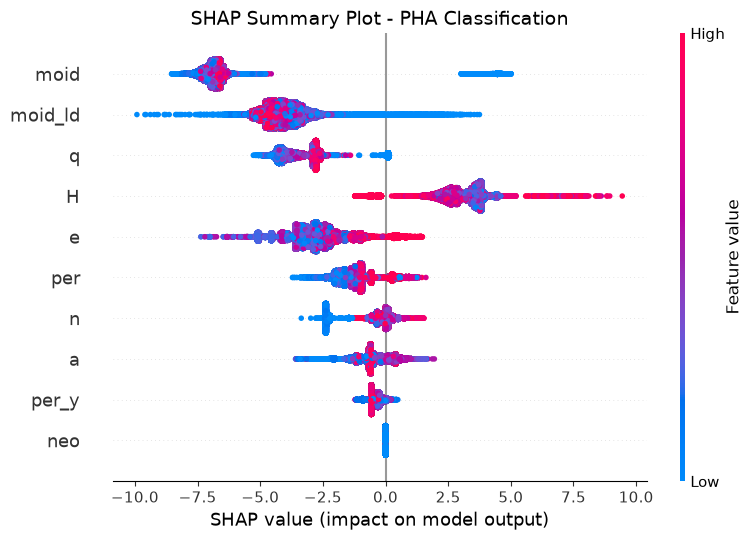

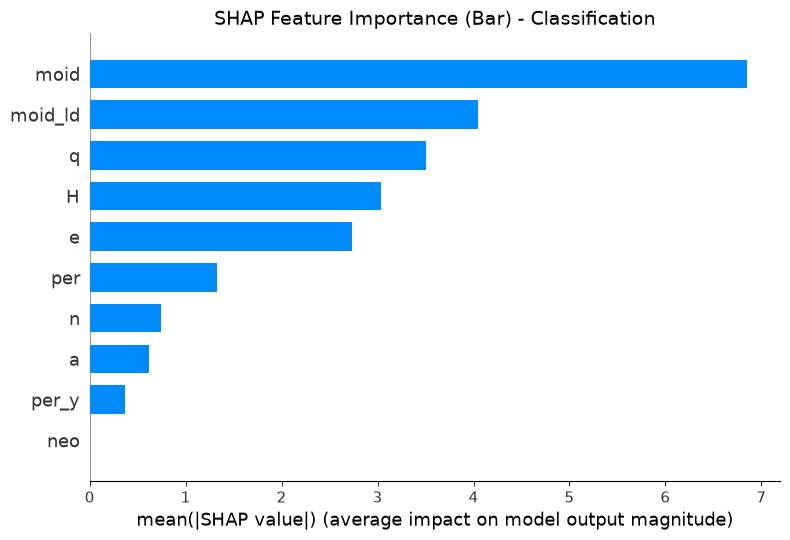

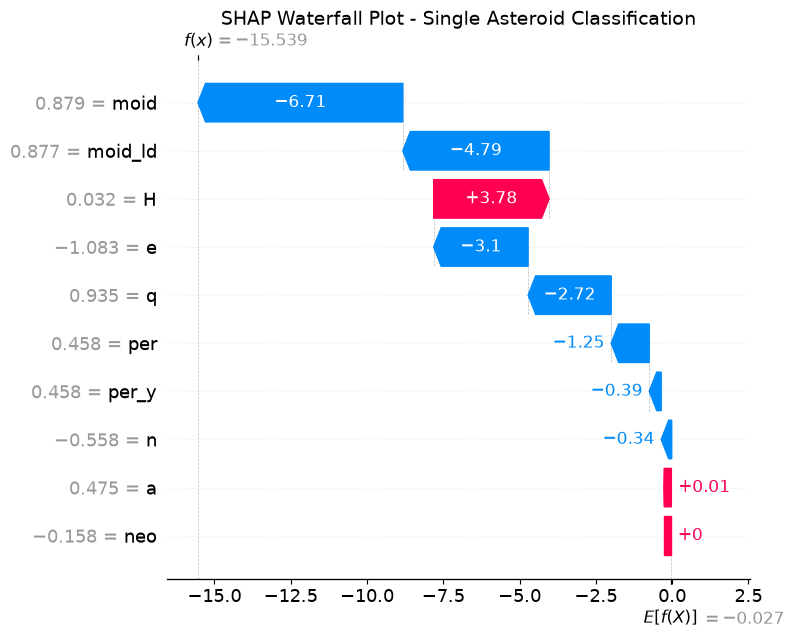

In [11]:
import joblib
import shap
import matplotlib.pyplot as plt
import pandas as pd

# Assume X_test_cls and X_test_reg are your test feature sets from your pipeline
# (or reload them from your data files if needed)

# ==========================================================
# 1. EXPLAIN CLASSIFICATION MODEL (PHA Status)
# ==========================================================
print("==================================================")
print(" GENERATING SHAP EXPLANATIONS FOR CLASSIFICATION")
print("==================================================")

# Load saved classification pipeline
best_cls_pipeline = joblib.load('best_pha_model.pkl')

# Extract the underlying classifier from the pipeline (whether SMOTE pipeline or Baseline)
if hasattr(best_cls_pipeline, 'named_steps'):
    cls_model = best_cls_pipeline.named_steps['classifier']
else:
    cls_model = best_cls_pipeline

# Initialize TreeExplainer for XGBoost/Random Forest classifier
cls_explainer = shap.TreeExplainer(cls_model)
cls_shap_values = cls_explainer(X_test_cls)

# For binary classification, select Class 1 (Hazardous) if 3D array
if len(cls_shap_values.shape) == 3:
    cls_shap_class1 = cls_shap_values[:, :, 1]
else:
    cls_shap_class1 = cls_shap_values

# Classification Plot 1: Summary (Bee Swarm) Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(cls_shap_class1, X_test_cls, plot_type="dot", show=False)
plt.title("SHAP Summary Plot - PHA Classification", fontsize=14)
plt.tight_layout()
plt.show()

# Classification Plot 2: Feature Importance Bar Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(cls_shap_class1, X_test_cls, plot_type="bar", show=False)
plt.title("SHAP Feature Importance (Bar) - Classification", fontsize=14)
plt.tight_layout()
plt.show()

# Classification Plot 3: Individual Waterfall Plot (First Asteroid)
plt.figure(figsize=(10, 6))
shap.plots.waterfall(cls_shap_class1[0], show=False)
plt.title("SHAP Waterfall Plot - Single Asteroid Classification", fontsize=14)
plt.tight_layout()
plt.show()

[INFO] Initializing SHAP TreeExplainer for XGBoost Classification Model...
[INFO] Generating SHAP Summary Plot (Bee Swarm) - Classification...


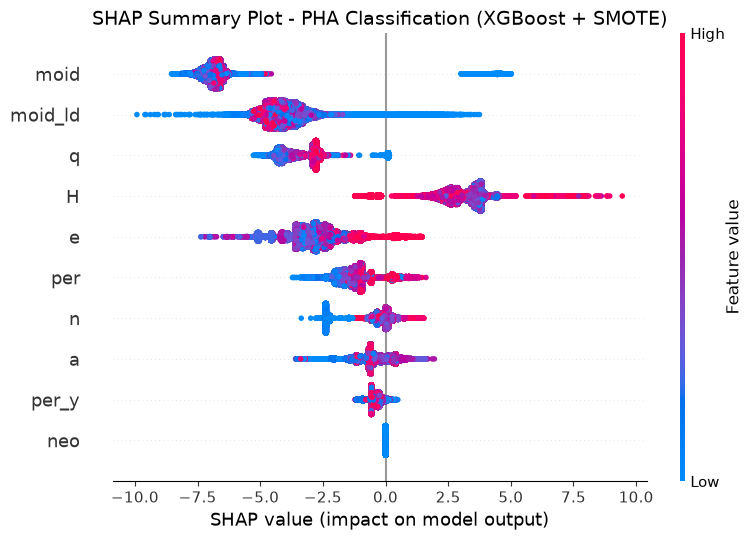

[INFO] Generating SHAP Feature Importance Plot (Bar) - Classification...


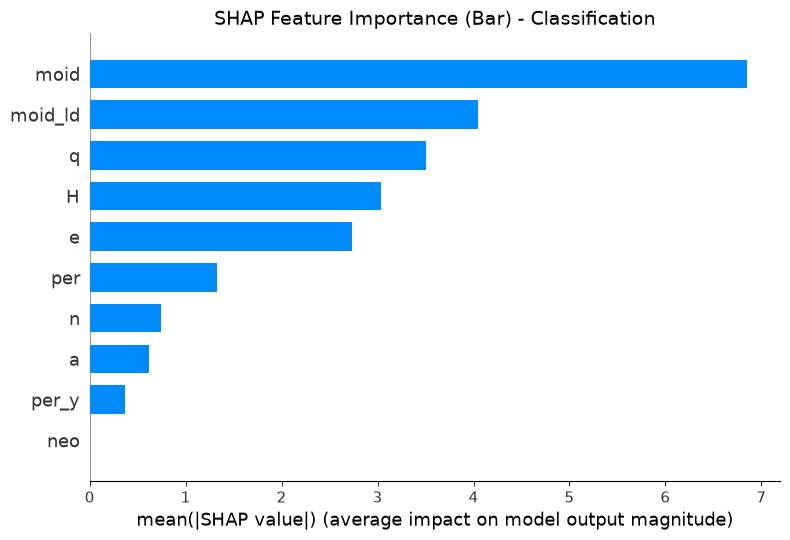

[INFO] Generating SHAP Waterfall Plot for a Single Asteroid...


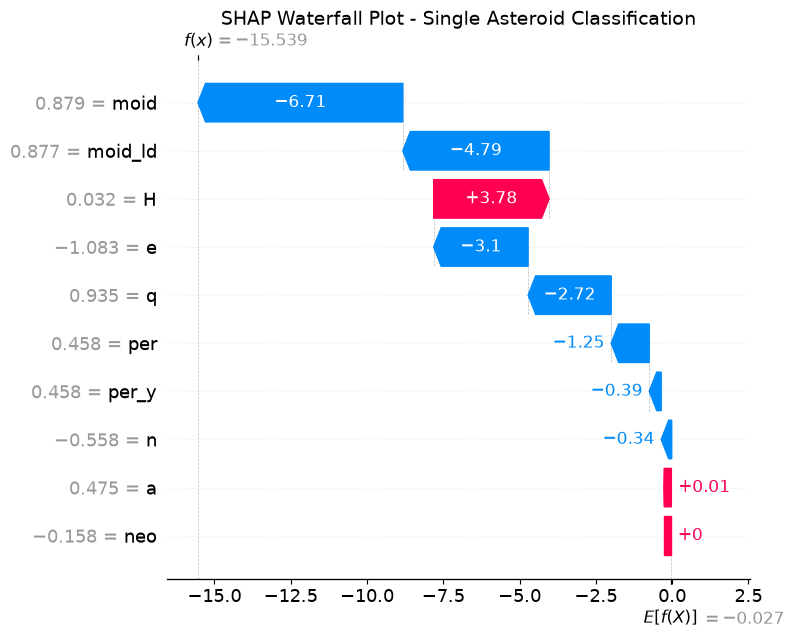

In [12]:
import joblib
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Load classification data and recreate the test set
X_cls_selected = joblib.load('X_cls_selected.pkl')
y_cls = joblib.load('y_cls.pkl')

_, X_test_cls, _, y_test_cls = train_test_split(
    X_cls_selected, y_cls, test_size=0.3, random_state=42, stratify=y_cls
)

# 2. Load your saved classification pipeline (SMOTE + XGBoost)
best_cls_pipeline = joblib.load('best_pha_model.pkl')

# 3. Extract the trained XGBoost classifier from the pipeline steps
cls_model = best_cls_pipeline.named_steps['classifier']

print(f"[INFO] Initializing SHAP TreeExplainer for XGBoost Classification Model...")
explainer = shap.TreeExplainer(cls_model)
shap_values = explainer(X_test_cls)

# Handle binary classification shape (if 3D, extract Class 1 / Hazardous)
if len(shap_values.shape) == 3:
    shap_values_class1 = shap_values[:, :, 1]
else:
    shap_values_class1 = shap_values

# ==========================================================
# PLOT 1: SUMMARY PLOT (Bee Swarm Plot)
# ==========================================================
print("[INFO] Generating SHAP Summary Plot (Bee Swarm) - Classification...")
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_test_cls, plot_type="dot", show=False)
plt.title("SHAP Summary Plot - PHA Classification (XGBoost + SMOTE)", fontsize=14)
plt.tight_layout()
plt.show()

# ==========================================================
# PLOT 2: FEATURE IMPORTANCE PLOT (Mean Absolute Bar Plot)
# ==========================================================
print("[INFO] Generating SHAP Feature Importance Plot (Bar) - Classification...")
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_test_cls, plot_type="bar", show=False)
plt.title("SHAP Feature Importance (Bar) - Classification", fontsize=14)
plt.tight_layout()
plt.show()

# ==========================================================
# PLOT 3: INDIVIDUAL PREDICTION PLOT (Waterfall Plot)
# ==========================================================
print("[INFO] Generating SHAP Waterfall Plot for a Single Asteroid...")
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values_class1[0], show=False)
plt.title("SHAP Waterfall Plot - Single Asteroid Classification", fontsize=14)
plt.tight_layout()
plt.show()